<a href="https://colab.research.google.com/github/hmbholamajhi-eng/Random_Forest_Heart_Disease_Classification/blob/main/BHOLA_SANKAR_Random_Forest_Heart_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predictive Classification Using Random Forest Ensembles
**Heart Disease Dataset |
 Kaggle Link:https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset?**

**Student:** Bhola Sankar Majhi (SEP BATCH)

---

## 1. Project Overview
- This notebook builds a **Random Forest classifier** that predicts a binary label (`target`) from 13 patient measurements.
- Workflow: inspect the data → explore it → clean it → split it → train a baseline model → evaluate it → tune it → compare baseline vs tuned → select the final model.
- After every important step there is a short explanation that uses the **actual outputs** of this notebook.
- This is a **learning project**. The model is **not clinically validated** and must not be used to diagnose anyone.

## 2. Problem Statement
- **Task:** binary classification. Given 13 measurements (age, sex, chest pain type, blood pressure, cholesterol, heart rate, ECG-related values and others), predict whether a record belongs to class `0` or class `1` of the column `target`.
- **Positive class:** `target = 1`. All precision, recall, F1 and ROC numbers in this notebook treat class 1 as the positive class.
- **Label meaning is NOT verified.** The CSV has no data dictionary, so this notebook cannot confirm what 0 and 1 stand for. Many tutorials say "1 = heart disease present", but that is only an assumption here (see Section 7.4 for why it needs checking). The notebook therefore says **class 0 / class 1** and states clearly where the real meaning matters.

## 3. Project Objectives
- Inspect and clean the heart disease data (missing values, duplicates, data types, outliers).
- Explore the data with plots (target distribution, feature distributions, feature-vs-target plots, correlation heatmap).
- Split the cleaned data into a training set and a held-out test set.
- Train a **baseline Random Forest** and evaluate it with accuracy, precision, recall, F1-score, confusion matrix and ROC-AUC.
- Study **feature importance** from the baseline model.
- Tune the Random Forest with **GridSearchCV** (training data only) and evaluate the tuned model on the same test set.
- Compare baseline vs tuned model, select the final model, and state the limitations honestly.

## 4. Dataset Overview
- **File:** `heart.csv` — 13 input columns and 1 target column. The column names match the widely used UCI-style heart disease datasets.
- **Source documentation:** not supplied with this project. The exact origin and the exact meaning of the integer codes are **not verified** here.

| Column | Plain-language description (standard name) | Kind of value |
|---|---|---|
| `age` | Age in years | number |
| `sex` | Sex (coded 0/1) | coded category |
| `cp` | Chest pain type | coded category (0–3) |
| `trestbps` | Resting blood pressure | number |
| `chol` | Serum cholesterol | number |
| `fbs` | Fasting blood sugar above a threshold (0/1) | coded category |
| `restecg` | Resting ECG result | coded category (0–2) |
| `thalach` | Maximum heart rate achieved | number |
| `exang` | Exercise-induced angina (0/1) | coded category |
| `oldpeak` | ST depression during exercise | decimal number |
| `slope` | Slope of the peak exercise ST segment | coded category (0–2) |
| `ca` | Number of major vessels (0–4) | coded category |
| `thal` | Thalassemia test result | coded category (0–3) |
| `target` | Label to predict (0 or 1) | coded category |

> The code values of `cp`, `restecg`, `slope`, `ca` and `thal` are whole numbers. Their exact meanings were **not** verified, so this notebook does not rely on them.

**Four different data objects are used. Do not mix them up:**

| Name | What it is | Rows |
|---|---|---|
| `df` | **Original dataset**, exactly as loaded | 1,025 |
| `df_clean` | **Cleaned dataset** (exact duplicate rows removed) | 302 |
| `X_train`, `y_train` | **Training set** (80% of `df_clean`) | 241 |
| `X_test`, `y_test` | **Test set** (20% of `df_clean`), used only for final evaluation | 61 |

## 5. Importing Libraries
- `pandas` and `numpy` handle the data, `matplotlib` and `seaborn` draw the plots.
- The scikit-learn imports (model, metrics, GridSearchCV) are placed in the cell where they are first used, so each step stays self-explanatory.

In [ ]:
# Import the core libraries used throughout the project.
import pandas as pd                # tables (DataFrames) and data handling
import numpy as np                 # numerical helpers
import matplotlib.pyplot as plt    # basic plotting
import seaborn as sns              # statistical plots (boxplots, heatmaps, countplots)

# Use a clean white-grid style for all plots.
sns.set_theme(style='whitegrid')

## 6. Loading the Data and Initial Data Inspection

In [ ]:
# Load the CSV file into a DataFrame called df (the ORIGINAL dataset).
# In Google Colab a file-upload dialog opens; outside Colab the local file "heart.csv" is read instead.
try:
    from google.colab import files
    uploaded = files.upload()
    csv_file = next(iter(uploaded))
except ImportError:
    csv_file = "heart.csv"
df = pd.read_csv(csv_file)

# First look: number of rows and columns.
print('Shape:', df.shape)
df.head()   # (output not shown here because it is not the last line of the cell)

# Basic quality checks on the original data: shape, missing values, duplicates, target counts.
print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nTarget distribution:")
print(df["target"].value_counts())

print("\nTarget percentages:")
print(df["target"].value_counts(normalize=True) * 100)

Saving heart.csv to heart (2).csv
Shape: (1025, 14)
Dataset shape: (1025, 14)

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows: 723

Target distribution:
target
1    526
0    499
Name: count, dtype: int64

Target percentages:
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64


### 6.1 Interpretation — shape, missing values, duplicates, target counts
**What was done:** loaded the CSV and printed its shape, missing values per column, duplicate rows and target counts.

**Why:** these checks show whether the data must be cleaned before modelling.

**What the output shows:**
- Shape: **1,025 rows × 14 columns** (13 inputs + `target`).
- Missing values: **0** in every column.
- Exact duplicate rows: **723** (about 70.5% of the file).
- Target counts: class 1 = **526** (51.32%), class 0 = **499** (48.68%).

**What it means:** no missing-value handling is needed, but the duplicate count is very large. Only 302 rows will remain after duplicates are removed (Section 8).

**Conclusion:** the file is complete but heavily repeated. This must be dealt with before any model is trained.

In [ ]:
# Show column names, data types and non-null counts of the original data.
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
# Count missing values per column (original data).
df.isnull().sum()

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalach,0
exang,0
oldpeak,0


In [ ]:
# Count rows that are exact copies of an earlier row (original data).
df.duplicated().sum()

np.int64(723)

### 6.2 Interpretation — data types, missing values, duplicate count
- `df.info()` shows 14 columns: **13 integer columns and 1 decimal column** (`oldpeak`). Every column has 1,025 non-null values.
- `df.isnull().sum()` confirms **0 missing values** in every column.
- `df.duplicated().sum()` confirms **723 duplicate rows**, the same number printed in Section 6.1.
- Every feature is already numeric, so no text-to-number conversion is needed.

In [ ]:
# Re-check duplicates and target balance, and list the unique target values.
print("Duplicate rows:", df.duplicated().sum())

# Check target class distribution (sorted so class 0 is printed first).
print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

# Check target class percentages.
print("\nTarget percentages:")
print((df["target"].value_counts(normalize=True).sort_index() * 100).round(2))

# The target must contain only two values for binary classification.
print("\nUnique target values:", sorted(df["target"].unique()))

# Statistical summary (count, mean, std, min, quartiles, max) of every column.
display(df.describe().T)

Duplicate rows: 723

Target distribution:
target
0    499
1    526
Name: count, dtype: int64

Target percentages:
target
0    48.68
1    51.32
Name: proportion, dtype: float64

Unique target values: [np.int64(0), np.int64(1)]


,count,mean,std,min,25%,50%,75%,max
age,1025.0,54.434146,9.072290,29.0,48.0,56.0,61.0,77.0
sex,1025.0,0.695610,0.460373,0.0,0.0,1.0,1.0,1.0
cp,1025.0,0.942439,1.029641,0.0,0.0,1.0,2.0,3.0
trestbps,1025.0,131.611707,17.516718,94.0,120.0,130.0,140.0,200.0
chol,1025.0,246.000000,51.592510,126.0,211.0,240.0,275.0,564.0
fbs,1025.0,0.149268,0.356527,0.0,0.0,0.0,0.0,1.0
restecg,1025.0,0.529756,0.527878,0.0,0.0,1.0,1.0,2.0
thalach,1025.0,149.114146,23.005724,71.0,132.0,152.0,166.0,202.0
exang,1025.0,0.336585,0.472772,0.0,0.0,0.0,1.0,1.0
oldpeak,1025.0,1.071512,1.175053,0.0,0.0,0.8,1.8,6.2


### 6.3 Interpretation — target values and summary statistics (original data)
**What was done:** repeated the duplicate and target checks, and printed `describe()` for every column.

**What the output shows:**
- `target` has exactly two values, **0 and 1**, so this is a binary classification problem.
- Ranges in the original data: `age` 29–77 (mean about 54.4), `trestbps` 94–200 (mean about 131.6), `chol` 126–564 (mean 246.0), `thalach` 71–202 (mean about 149.1).
- `sex` has a mean of about 0.70, so roughly 70% of rows have `sex = 1`. The data is **not balanced between the two sex codes**.
- `fbs` has a mean of about 0.15, so only about 15% of rows have `fbs = 1`.
- `chol` has a maximum of 564, far above its 75th percentile (275). This is a possible extreme value (checked in Section 8.4).

**What it means:** these averages include repeated rows. They are recomputed on the cleaned data in Section 8.3.

## 7. Exploratory Data Analysis (EDA)
> **Note:** Sections 7.1–7.4 were done on the **original** dataset `df` (1,025 rows, with duplicates). Cleaned-data versions of the key plots are in Section 8.6, so you can compare both.

### 7.1 Target Class Distribution

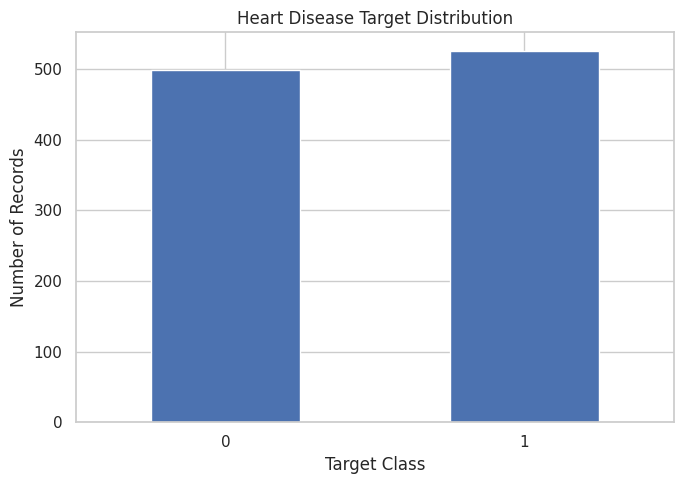

In [ ]:
# Bar chart of the number of records in each target class (original data).
import matplotlib.pyplot as plt

# Count rows per class and sort by class label so class 0 comes first.
target_counts = df["target"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
target_counts.plot(kind="bar")

plt.title("Heart Disease Target Distribution")
plt.xlabel("Target Class")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

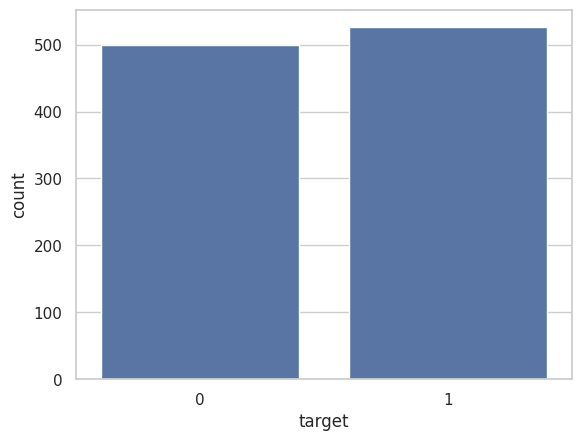

In [ ]:
# Same information as a seaborn countplot (a second view of the target balance).
sns.countplot(x='target', data=df)
plt.show()

### 7.1 Interpretation — target distribution (original data)
**What was done:** plotted the number of records in each class twice (matplotlib bars and a seaborn countplot).

**What the output shows:** class 0 has 499 records (48.68%) and class 1 has 526 records (51.32%). The two bars are almost the same height.

**What it means:** the classes are **nearly balanced**, so class imbalance is not a major problem and accuracy is not badly misleading. After duplicates are removed the split is 138 vs 164 (45.7% vs 54.3%, Section 8.5), which is still only mildly unbalanced.

**Conclusion:** no resampling is needed. The existing model setting `class_weight="balanced"` is kept as a safeguard.

### 7.2 Univariate Analysis — Numerical Features

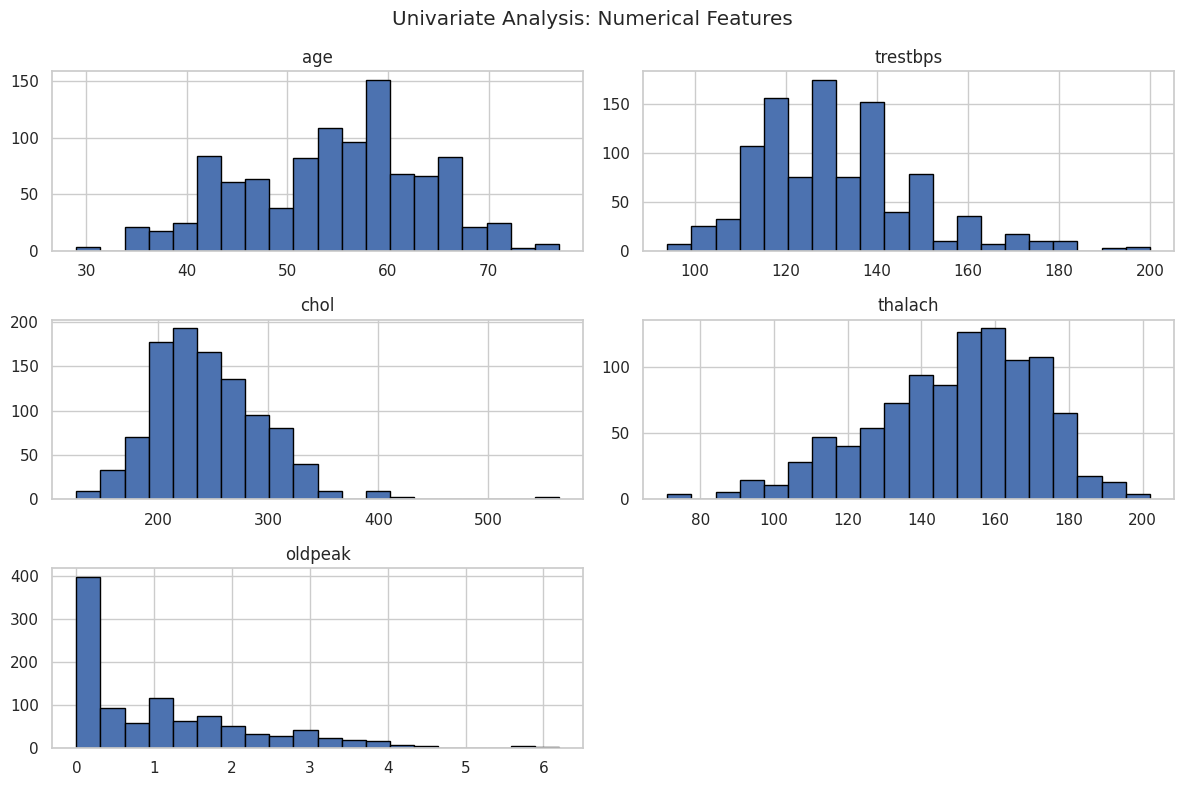

In [ ]:
# Histograms of the five numerical features (original data, 20 bins each).
import matplotlib.pyplot as plt

# These five columns are true numbers; the other columns are coded categories.
numerical_cols = [
    "age", "trestbps", "chol",
    "thalach", "oldpeak"
]

df[numerical_cols].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Univariate Analysis: Numerical Features")
plt.tight_layout()
plt.show()

### 7.2 Interpretation — numerical feature distributions (original data)
**What was done:** drew a histogram for `age`, `trestbps`, `chol`, `thalach` and `oldpeak`.

**What the plots show:**
- `age`: spread from about 29 to 77, with the tallest bar near 58–60.
- `trestbps` (resting blood pressure): centred around 120–140 with a thin tail up to 200.
- `chol` (cholesterol): most values lie between about 200 and 300; a few very high values reach 564.
- `thalach` (maximum heart rate): leans to the left; most values are between about 140 and 180.
- `oldpeak`: strongly skewed to the right; a very large group is at or near 0.

**What it means:** `chol`, `trestbps` and `oldpeak` have long right tails (possible extreme values). Some bars are inflated because repeated rows are counted several times in this original data.

**Conclusion:** the features have different ranges and shapes. This is acceptable for a Random Forest (see the scaling decision in Section 8.7).

### 7.3 Bivariate Analysis — Features vs Target

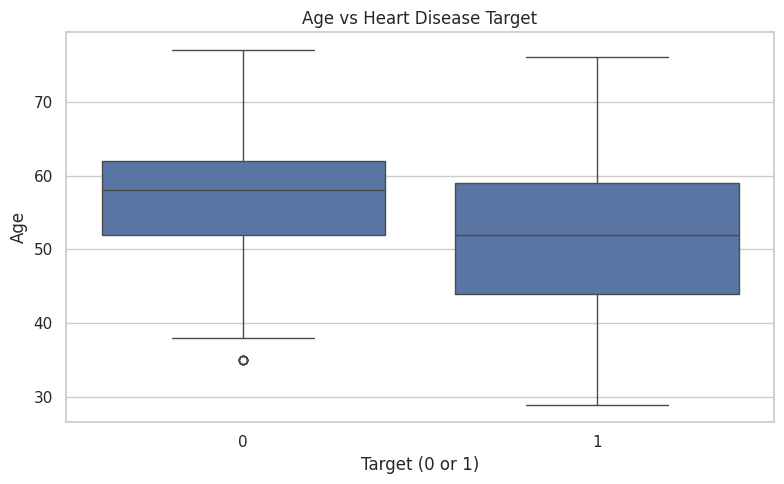

In [ ]:
# Age vs Target (original data): boxplot compares the age spread in the two classes.
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="age")

plt.title("Age vs Heart Disease Target")
plt.xlabel("Target (0 or 1)")
plt.ylabel("Age")
plt.tight_layout()
plt.show()

### 7.3a Interpretation — age vs target (original data)
- **What the plot shows:** the median age of class 0 is about **58**; the median age of class 1 is about **52**. Class 1 has a wider age spread and includes the youngest records (down to about 29).
- **What it means:** class 1 tends to be somewhat younger than class 0, but the boxes overlap a lot, so age alone does not separate the classes.
- **Conclusion:** age has a modest relationship with `target` (correlation about −0.23 in Section 7.4). This is an association, not a cause.

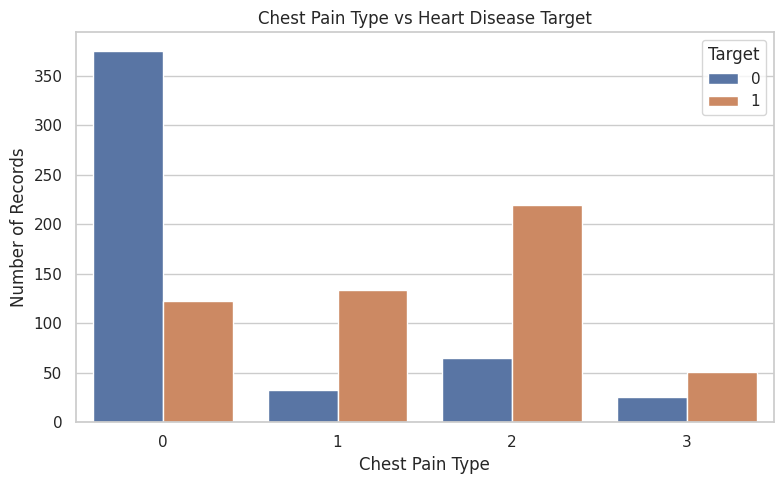

In [ ]:
# Chest pain type (cp) vs Target (original data): bars show how many records of each class fall in each cp value.
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="cp", hue="target")

plt.title("Chest Pain Type vs Heart Disease Target")
plt.xlabel("Chest Pain Type")
plt.ylabel("Number of Records")
plt.legend(title="Target")
plt.tight_layout()
plt.show()

### 7.3b Interpretation — chest pain type (`cp`) vs target (original data)
- **What the plot shows:** for `cp = 0`, class 0 is much larger (about 375 records vs about 122 for class 1). For `cp = 1`, `2` and `3`, class 1 is larger (for example about 220 vs 65 for `cp = 2`).
- **What it means:** `cp` separates the two classes clearly. This agrees with `cp` being the top feature in the Random Forest (Section 14) and with its correlation of about +0.43 with `target`.
- **Conclusion:** `cp` is one of the most informative features. The plot counts include repeated rows.

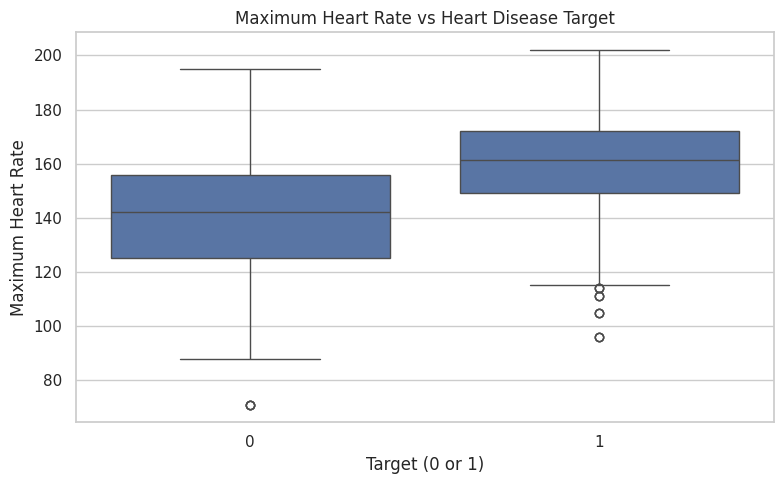

In [ ]:
# Maximum heart rate (thalach) vs Target (original data).
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="thalach")

plt.title("Maximum Heart Rate vs Heart Disease Target")
plt.xlabel("Target (0 or 1)")
plt.ylabel("Maximum Heart Rate")
plt.tight_layout()
plt.show()

### 7.3c Interpretation — maximum heart rate (`thalach`) vs target (original data)
- **What the plot shows:** class 1 has a clearly higher maximum heart rate (median about **161**) than class 0 (median about **142**). The middle 50% of the two classes overlap only partly. Class 1 also has a few low outliers (about 96–114).
- **What it means:** `thalach` is a useful separating feature, which matches its second place in the feature importance ranking and its correlation of about +0.42 with `target`.
- **Conclusion:** higher `thalach` goes with class 1 in this data (association only).

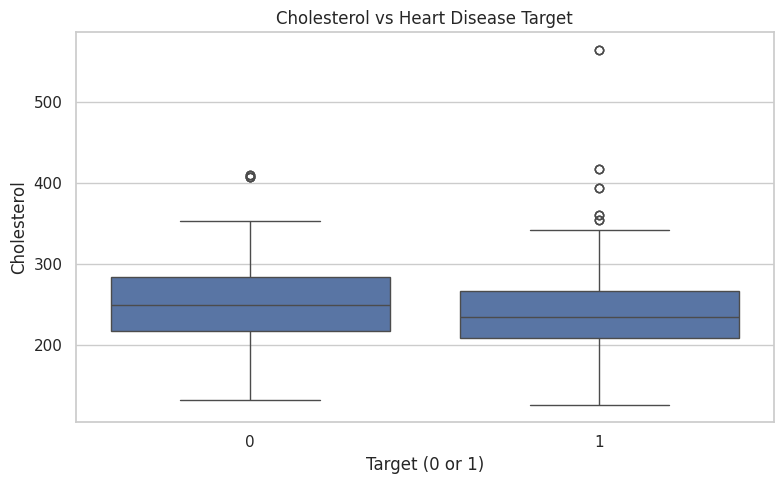

In [ ]:
# Cholesterol (chol) vs Target (original data).
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="target", y="chol")

plt.title("Cholesterol vs Heart Disease Target")
plt.xlabel("Target (0 or 1)")
plt.ylabel("Cholesterol")
plt.tight_layout()
plt.show()

### 7.3d Interpretation — cholesterol (`chol`) vs target (original data)
- **What the plot shows:** the medians are close (class 0 about 249, class 1 about 234) and the boxes overlap heavily. Both classes have high outliers; the highest point (about 564) belongs to class 1.
- **What it means:** cholesterol alone separates the classes **poorly**. Its correlation with `target` is only about −0.10.
- **Conclusion:** `chol` is weak on its own. Its mid-range importance in the Random Forest (Section 14) should be read with care.

### 7.4 Multivariate Analysis — Correlation Heatmap

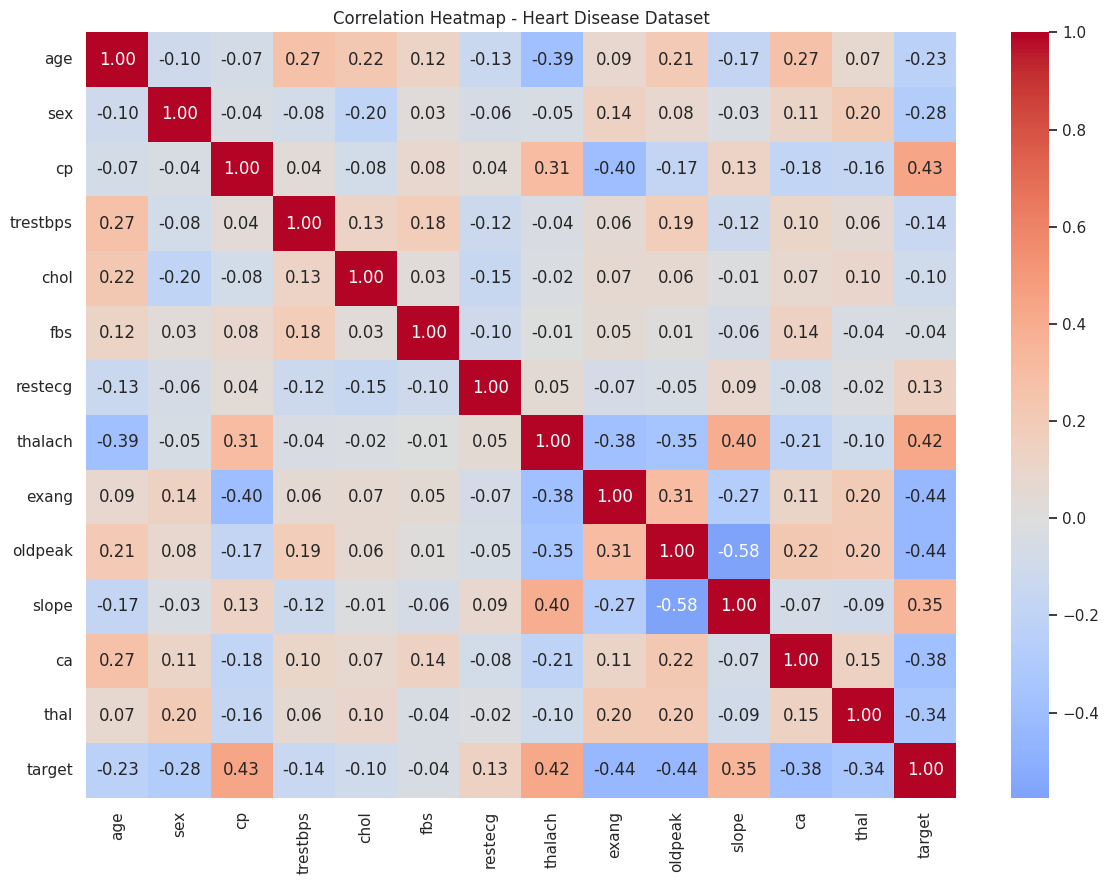

In [ ]:
# Correlation heatmap of all columns (original data): each cell shows the linear relationship between two columns (-1 to +1).
plt.figure(figsize=(12, 9))

# Pearson correlation between every pair of numeric columns.
correlation = df.corr(numeric_only=True)

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0)

plt.title("Correlation Heatmap - Heart Disease Dataset")
plt.tight_layout()
plt.show()

### 7.4 Interpretation — correlation heatmap (original data)
**What was done:** computed the correlation between every pair of columns and showed it as a colour-coded heatmap.

**What the plot shows (values read from the heatmap):**
- Strongest links **with `target`**: `exang` (−0.44), `oldpeak` (−0.44), `cp` (+0.43), `thalach` (+0.42), `ca` (−0.38), `slope` (+0.35), `thal` (−0.34), `sex` (−0.28), `age` (−0.23).
- Weak links with `target`: `fbs` (−0.04), `chol` (−0.10), `restecg` (+0.13), `trestbps` (−0.14).
- Strongest links **between features**: `oldpeak` and `slope` (−0.58), `cp` and `exang` (−0.40), `thalach` and `slope` (+0.40), `thalach` and `age` (−0.39).

**What it means:** no feature is almost perfectly related to `target` (the largest value is about 0.44), so the problem needs several features together. No pair of features is almost identical (largest about 0.58), so there is no extreme feature duplication.

**Correlation is not causation.** It only shows that two columns move together in this dataset.

**Label meaning needs checking:** class 1 has *higher* `thalach` and *lower* `exang`, `oldpeak` and `ca` than class 0. In the usual clinical reading of these measurements, exercise-induced angina, larger ST depression and more blocked vessels go with **more** heart disease, and a lower maximum heart rate also goes with more disease. Here class 1 shows the **opposite** pattern. This suggests class 1 could be the *less severe / no-disease* group in this copy of the data — the reverse of the common "1 = disease" assumption. This is an **inference from the pattern, not a verified fact**. Check the original source documentation before describing class 1 as "disease present" in any report.

## 8. Data Cleaning and Preprocessing
> From here on, all analysis and modelling use the **cleaned dataset `df_clean`**, not the original `df`.

### 8.1 Summary of the original data and duplicate removal

In [ ]:
# Summary of the problems found in the original data before cleaning.
print("Original dataset:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())
print("Missing values:", df.isnull().sum().sum())
print("Target distribution:")
print(df["target"].value_counts())

Original dataset: (1025, 14)
Exact duplicate rows: 723
Missing values: 0
Target distribution:
target
1    526
0    499
Name: count, dtype: int64


In [ ]:
# Create a working copy so the original DataFrame df stays untouched.
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (1025, 14)
Working dataset shape: (1025, 14)


In [ ]:
# Check duplicate records before cleaning.
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

# Remove exact duplicate rows (the first copy of each row is kept).
df_clean = df_clean.drop_duplicates().copy()

# Confirm the new size and that no duplicates remain.
print("Shape after removing duplicates:", df_clean.shape)
print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 723
Shape after removing duplicates: (302, 14)
Duplicate rows after cleaning: 0


### 8.1 Interpretation — duplicate removal
**What was done:** made a copy of the data (`df_clean`) and removed every row that was an exact copy of an earlier row.

**Why:** if identical rows stay in the data, a copy of a training row can land in the test set. The model would then be tested on data it has already seen and the test score would look better than it really is (data leakage).

**What the output shows:** the data shrank from **1,025 rows to 302 rows**. **723 rows were removed** and **0 duplicates remain**.

**What it means:**
- About 70.5% of the original file was exact repetition, so the dataset is **less than a third of its original size**. This is a big change and it is reported openly.
- The 302 remaining rows are unique as *sets of 14 values*. This does **not** prove that they are 302 different patients. Two different patients can share identical values, and a repeated record may also be a copy or merge error in the data source. **The original data source and the reason for the repeated records should be investigated.**
- A smaller dataset gives less stable results (see the 61-row test set in Section 9).

**Conclusion:** duplicates must be removed for an honest evaluation. All later work uses `df_clean` (302 rows).

### 8.2 Missing values, data types and category checks (cleaned data)

In [ ]:
# Check missing values again after duplicate removal.
print("Missing values in each column:")

print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Total missing values: 0


In [ ]:
# Check column data types and non-null counts of the cleaned data.
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 878
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


In [ ]:
# Check that each coded column contains only the values we expect.
# NOTE: these expected ranges are assumptions about this dataset (not taken from official documentation).
expected_categories = {
    "sex": [0, 1],
    "cp": [0, 1, 2, 3],
    "fbs": [0, 1],
    "restecg": [0, 1, 2],
    "exang": [0, 1],
    "slope": [0, 1, 2],
    "ca": [0, 1, 2, 3, 4],
    "thal": [0, 1, 2, 3],
    "target": [0, 1]
}

for col, expected in expected_categories.items():

    # Values that actually occur in the column.
    actual = set(df_clean[col].dropna().unique())

    # Values that occur but are not in the expected list (should be empty).
    unexpected = actual - set(expected)

    print(f"{col}: Unexpected values = {sorted(unexpected)}")

sex: Unexpected values = []
cp: Unexpected values = []
fbs: Unexpected values = []
restecg: Unexpected values = []
exang: Unexpected values = []
slope: Unexpected values = []
ca: Unexpected values = []
thal: Unexpected values = []
target: Unexpected values = []


### 8.2 Interpretation — missing values, data types and category values
- **Missing values:** still **0** in every column, so no imputation is needed.
- **Data types:** all **302** rows are non-null; 13 columns are integers and `oldpeak` is a decimal. The row index still runs up to 878 because removing duplicates left gaps in the original index labels. This is harmless.
- **Category check:** every coded column shows `Unexpected values = []`, so no value falls outside the ranges we expected.
- **Limit of this check:** the expected ranges were assumed by the author, so this only shows the values are *plausible*, not that their meaning is documented.
- **Conclusion:** the cleaned data is complete and consistent, ready for modelling.

### 8.3 Summary statistics (cleaned data)

In [ ]:
# Statistical summary of the CLEANED dataset (compare with the original summary in Section 6).
display(df_clean.describe().T)

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.420530,9.047970,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.682119,0.466426,0.0,0.00,1.0,1.00,1.0
cp,302.0,0.963576,1.032044,0.0,0.00,1.0,2.00,3.0
trestbps,302.0,131.602649,17.563394,94.0,120.00,130.0,140.00,200.0
chol,302.0,246.500000,51.753489,126.0,211.00,240.5,274.75,564.0
fbs,302.0,0.149007,0.356686,0.0,0.00,0.0,0.00,1.0
restecg,302.0,0.526490,0.526027,0.0,0.00,1.0,1.00,2.0
thalach,302.0,149.569536,22.903527,71.0,133.25,152.5,166.00,202.0
exang,302.0,0.327815,0.470196,0.0,0.00,0.0,1.00,1.0
oldpeak,302.0,1.043046,1.161452,0.0,0.00,0.8,1.60,6.2


### 8.3 Interpretation — summary statistics (cleaned data)
- Cleaned data: `age` mean about 54.42 (29–77), `trestbps` mean about 131.60 (94–200), `chol` mean 246.50 (126–564), `thalach` mean about 149.57 (71–202), `exang` mean about 0.33.
- These values are very close to the original-data values in Section 6.3, so removing duplicates **did not change the overall averages much**.
- The maximum `chol` is still 564, so the extreme value was not a duplicate artefact.
- **Conclusion:** the cleaned data has a similar overall profile to the original, but with 302 rows instead of 1,025.

### 8.4 Outlier Analysis (cleaned data)

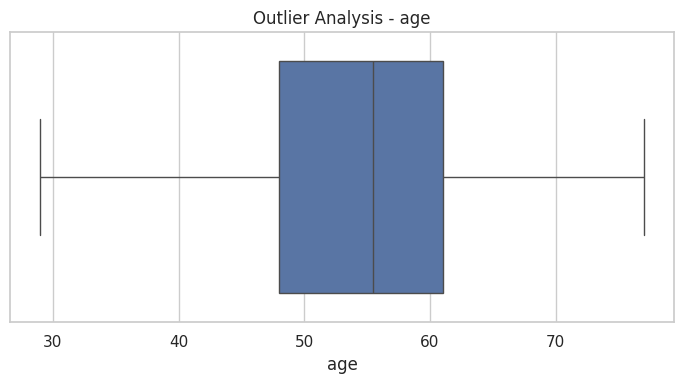

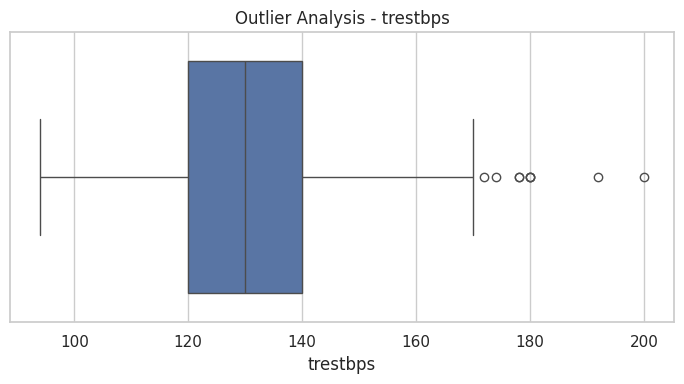

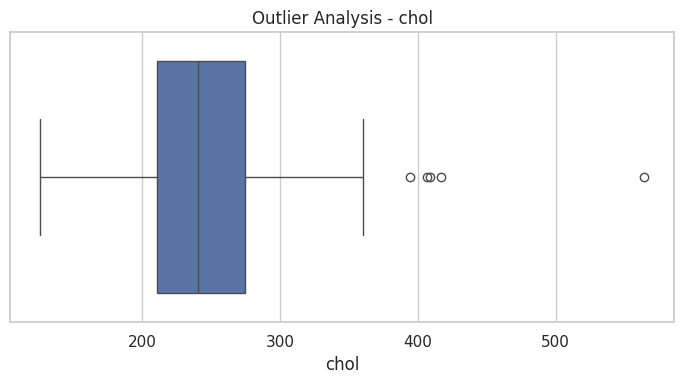

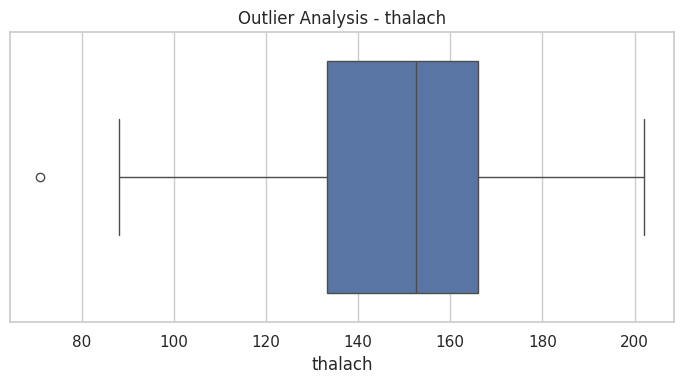

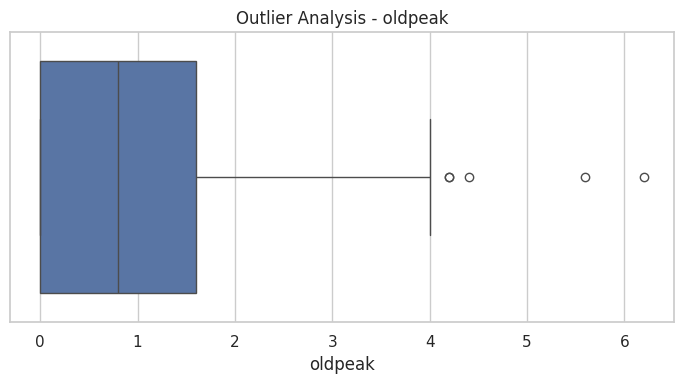

In [ ]:
# Boxplots of the numerical features of the cleaned data: dots outside the whiskers are potential outliers.
numerical_cols = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"]

for col in numerical_cols:

    plt.figure(figsize=(7, 4))

    sns.boxplot(data=df_clean, x=col)

    plt.title(f"Outlier Analysis - {col}")
    plt.xlabel(col)

    plt.tight_layout()
    plt.show()

In [ ]:
# Count outliers with the same rule as the boxplot whiskers (beyond 1.5 x IQR from the quartiles),
# and measure skewness (0 = symmetric, positive = long right tail, negative = long left tail).
for col in numerical_cols:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df_clean[col] < q1 - 1.5 * iqr) | (df_clean[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col:9s} outliers (IQR rule): {n_out:2d} | skewness: {df_clean[col].skew():.2f}")

# Median of three key features per target class (used in the interpretation of the cleaned boxplots).
print("\nMedian by target class:")
print(df_clean.groupby("target")[["age", "thalach", "chol"]].median())

age       outliers (IQR rule):  0 | skewness: -0.20
trestbps  outliers (IQR rule):  9 | skewness: 0.72
chol      outliers (IQR rule):  5 | skewness: 1.15
thalach   outliers (IQR rule):  1 | skewness: -0.53
oldpeak   outliers (IQR rule):  5 | skewness: 1.27

Median by target class:
         age  thalach   chol
target                      
0       58.0    142.0  249.0
1       52.0    161.0  234.5


### 8.4 Interpretation — outliers (cleaned data)
**What was done:** drew a boxplot for each numerical feature and counted the points beyond the whiskers (1.5 × IQR rule).

**What the output shows:** `age` has **0** outliers, `trestbps` has **9**, `chol` has **5**, `thalach` has **1** and `oldpeak` has **5**. `chol`, `oldpeak` and `trestbps` have long right tails (skewness 1.15, 1.27 and 0.72); `thalach` leans slightly left (−0.53).

**What it means / decision:** the outliers were **kept** (not removed and not capped) because:
- a Random Forest splits on thresholds, so a few extreme values do not stretch the model the way they stretch distance-based methods;
- the values look medically possible (for example `chol` = 564 is very high but not impossible), and there is no documentation proving they are errors;
- with only 302 rows, deleting more rows would hurt more than it helps.

**Conclusion:** no outlier treatment was applied. This is a deliberate choice, not an oversight.

### 8.5 Final dataset validation

In [ ]:
# Final check of the cleaned dataset before modelling.
print("Final dataset shape:", df_clean.shape)
print("Duplicate rows:", df_clean.duplicated().sum())
print("Total missing values:", df_clean.isnull().sum().sum())

print("\nTarget distribution:")
print(df_clean["target"].value_counts().sort_index())

# Class percentages of the cleaned data.
print("\nTarget percentages:")
print(
    (df_clean["target"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

Final dataset shape: (302, 14)
Duplicate rows: 0
Total missing values: 0

Target distribution:
target
0    138
1    164
Name: count, dtype: int64

Target percentages:
target
0    45.7
1    54.3
Name: proportion, dtype: float64


### 8.5 Interpretation — final validation
- The cleaned dataset has **302 rows × 14 columns**, **0 duplicates** and **0 missing values**.
- Class counts: class 0 = **138 (45.7%)**, class 1 = **164 (54.3%)**. Before cleaning it was 48.68% / 51.32%, so removing duplicates removed more class-1 copies than class-0 copies.
- **Conclusion:** the classes are still reasonably balanced (about 46 / 54). The cleaned data is ready for the train-test split.

### 8.6 EDA on the cleaned data
The plots below use `df_clean` (302 rows), so they match the data the model will actually use.

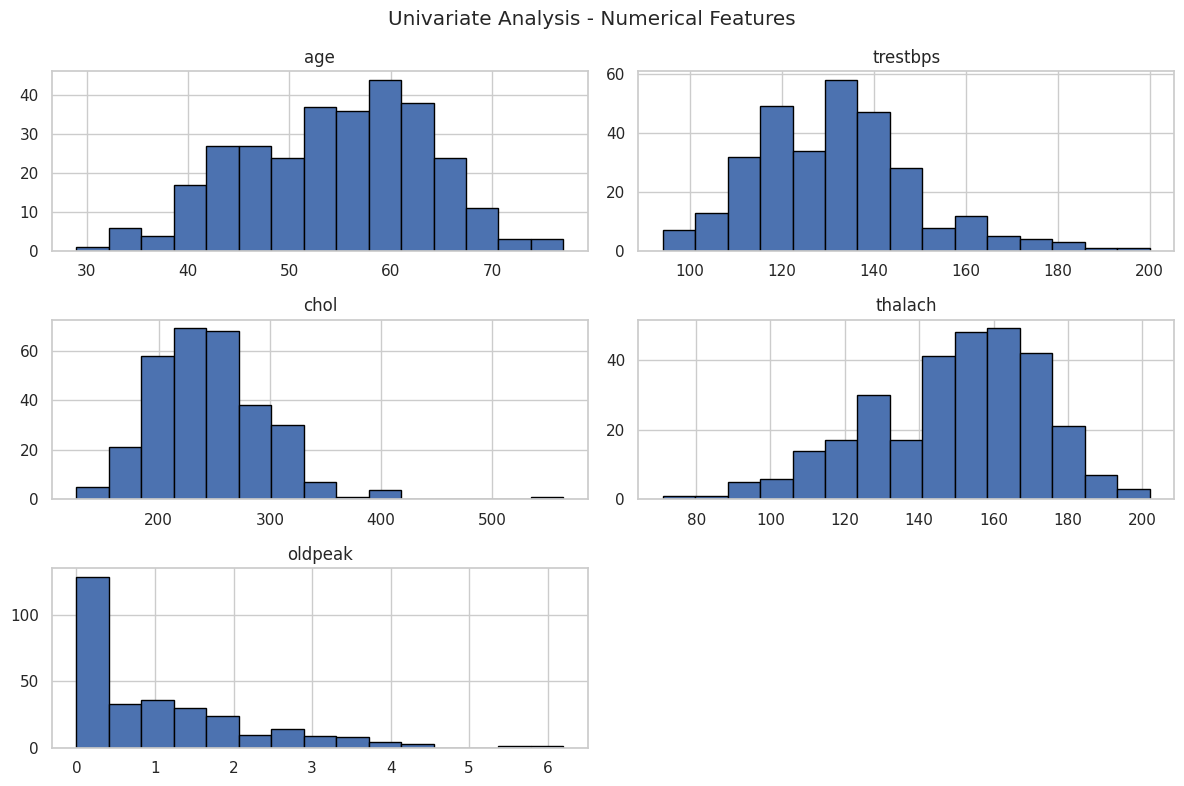

In [ ]:
# Histograms of the numerical features of the CLEANED data (15 bins each).
import matplotlib.pyplot as plt

numerical_cols = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak"
]

df_clean[numerical_cols].hist(
    figsize=(12, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Univariate Analysis - Numerical Features")
plt.tight_layout()
plt.show()

### 8.6a Interpretation — numerical features (cleaned data)
- The shapes are the same as in the original histograms (Section 7.2), but the counts are about a third as large and the artificial spikes caused by repeated rows are gone.
- `age`: tallest bar near 60. `trestbps`: centred near 120–140 with a thin right tail. `chol`: right-skewed with a few values above 400 and one near 564. `thalach`: left-skewed, most values between about 140 and 180. `oldpeak`: heavily right-skewed with the biggest group at 0–0.4 (more than 120 rows).
- **Conclusion:** the cleaned data keeps the same overall feature shapes, so cleaning did not distort the features.

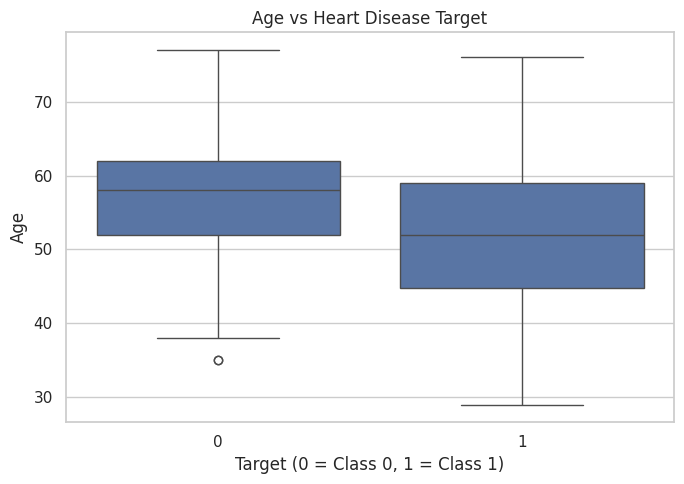

In [ ]:
# Age vs Target (cleaned data).
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="target",
    y="age"
)

plt.title("Age vs Heart Disease Target")
plt.xlabel("Target (0 = Class 0, 1 = Class 1)")
plt.ylabel("Age")

plt.tight_layout()
plt.show()

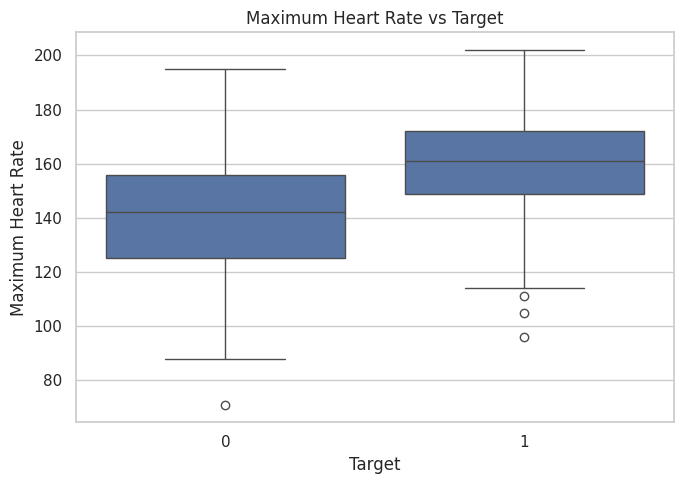

In [ ]:
# Maximum heart rate vs Target (cleaned data).
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df_clean,
    x="target",
    y="thalach"
)

plt.title("Maximum Heart Rate vs Target")
plt.xlabel("Target")
plt.ylabel("Maximum Heart Rate")

plt.tight_layout()
plt.show()   # plt.show() added: the original cell did not call it

### 8.6b Interpretation — age and maximum heart rate vs target (cleaned data)
- **Age:** the median age is **58** for class 0 and **52** for class 1 (from the median table in Section 8.4). Class 1 is again younger on average, with a wider spread.
- **Maximum heart rate:** the median `thalach` is **142** for class 0 and **161** for class 1. The class 1 box sits clearly higher.
- **What it means:** the pattern is the same as in the original data (Sections 7.3a and 7.3c), so duplicates were not creating these differences.
- **Conclusion:** both features are associated with `target`; `thalach` separates the classes more clearly than `age`.

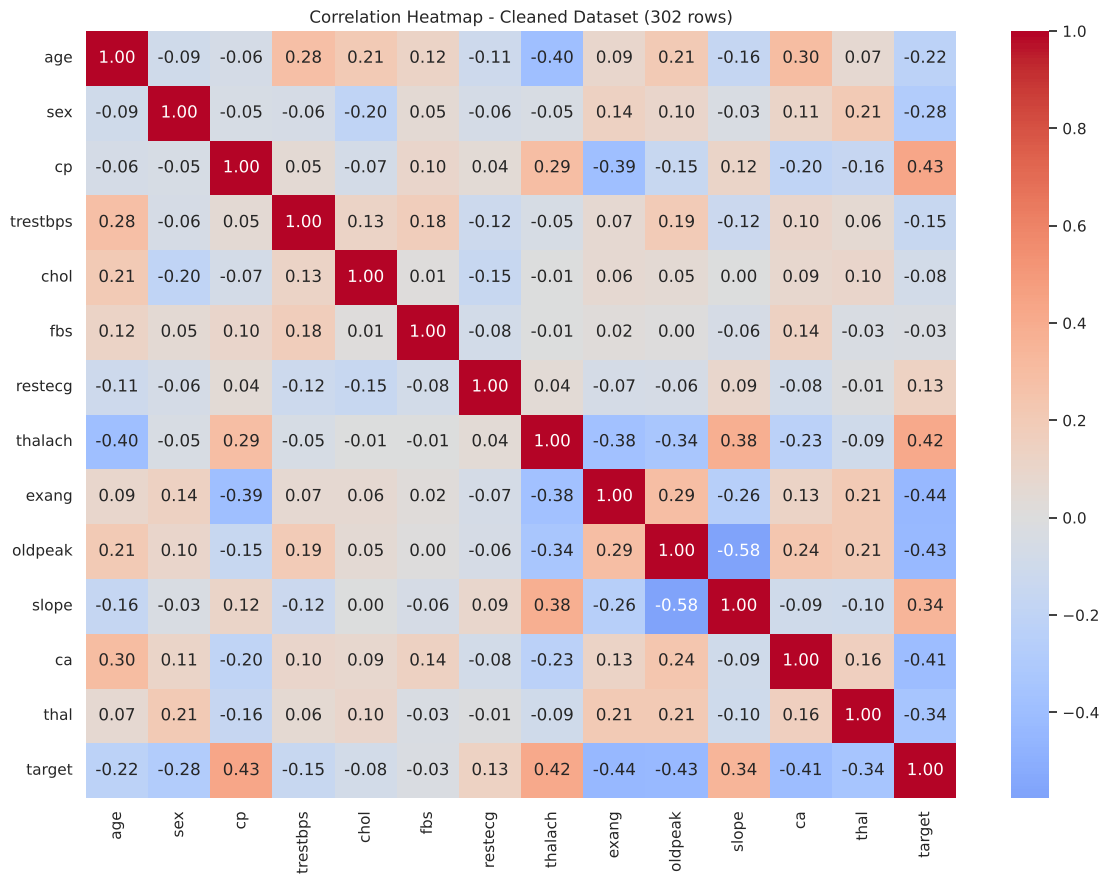

Correlation of each feature with target (cleaned data):
exang      -0.44
oldpeak    -0.43
ca         -0.41
thal       -0.34
sex        -0.28
age        -0.22
trestbps   -0.15
chol       -0.08
fbs        -0.03
restecg     0.13
slope       0.34
thalach     0.42
cp          0.43
Name: target, dtype: float64


In [ ]:
# Correlation heatmap of the CLEANED data (the data the model is trained on).
corr_clean = df_clean.corr(numeric_only=True)

plt.figure(figsize=(12, 9))
sns.heatmap(
    corr_clean,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0)

plt.title("Correlation Heatmap - Cleaned Dataset (302 rows)")
plt.tight_layout()
plt.show()

# Correlation of each feature with the target, from most negative to most positive.
print("Correlation of each feature with target (cleaned data):")
print(corr_clean["target"].drop("target").sort_values().round(2))

### 8.6c Interpretation — correlation heatmap (cleaned data)
**What the output shows:**
- Correlation with `target` (cleaned data): `cp` (+0.43), `thalach` (+0.42), `slope` (+0.34), `restecg` (+0.13) are positive; `exang` (−0.44), `oldpeak` (−0.43), `ca` (−0.41), `thal` (−0.34), `sex` (−0.28), `age` (−0.22), `trestbps` (−0.15), `chol` (−0.08), `fbs` (−0.03) are negative.
- Strongest links between two features: `oldpeak` and `slope` (−0.58), `age` and `thalach` (−0.40), `cp` and `exang` (−0.39), `thalach` and `slope` (+0.38).

**What it means:** the pattern is almost the same as in the original-data heatmap (Section 7.4). The largest change is that `ca` is slightly stronger after cleaning (−0.41 instead of −0.38). The strongest features are still `exang`, `oldpeak`, `cp`, `thalach` and `ca`; `fbs` and `chol` are still the weakest.

**Conclusion:** several features each carry a moderate signal and none is dominant. This is a good reason to use an ensemble of trees. Correlation is **not** causation, and the label-meaning warning from Section 7.4 still applies.

### 8.7 Feature Scaling and Encoding Decision
**Decision: feature scaling (for example `StandardScaler`) was NOT used.**

**Why:**
- A Random Forest is built from decision trees. A tree asks questions like "is `chol` above 240?". It only cares about the **order** of the values, not their size, so it is **not sensitive to feature magnitude** in the way distance-based methods (KNN, SVM) or gradient-based methods are.
- The features have very different ranges (`chol` up to 564, `oldpeak` up to about 6, binary columns 0/1). This does **not** hurt a Random Forest.
- Scaling would not improve the model and would add an extra step that must be fitted on the training set only to avoid leakage.

**Encoding:** all columns are already numeric, so no encoding was applied. The coded columns (`cp`, `slope`, `ca`, `thal`, `restecg`) are used as they are, and trees can split on them directly. One-hot encoding was not applied to keep the existing approach.

**Conclusion:** the model is trained on the 13 raw cleaned features. No scaler is used anywhere in this notebook.

## 9. Train-Test Split

In [ ]:
# Split the CLEANED data into a training set (80%) and a held-out test set (20%).
from sklearn.model_selection import train_test_split

# Separate input features from the target variable.
X = df_clean.drop(columns="target")

# Store the target labels for classification.
y = df_clean["target"]

# stratify=y keeps the class proportions equal in both parts; random_state=42 makes the split repeatable.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

# Check that both parts keep (almost) the same class proportions.
print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training features: (241, 13)
Testing features: (61, 13)

Training target distribution:
target
1    0.544
0    0.456
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.541
0    0.459
Name: proportion, dtype: float64


### 9 Interpretation — train-test split
**What was done:** split `df_clean` (302 rows) into **241 training rows** and **61 test rows** (80% / 20%), with stratification and `random_state=42`.

**Why:** the test set must stay unseen during training and tuning so that the final scores are an honest estimate on new data.

**What the output shows:**
- Training features: **(241, 13)**; test features: **(61, 13)**.
- Training classes: 54.4% class 1 and 45.6% class 0. Test classes: 54.1% class 1 and 45.9% class 0.

**What it means:**
- Stratification worked: both parts have almost the same class mix as the full cleaned data (54.3% class 1).
- The split was made **after** duplicate removal, so no identical row can sit in both parts.
- The test set is **small**. Each wrong prediction changes accuracy by about 1.6 percentage points (1 / 61), so the test scores are noisy (see Section 20).
- Based on the class mix, the test set holds 28 class-0 rows and 33 class-1 rows (the same totals appear as "support" in the classification reports below).

**Conclusion:** the split is valid and reproducible. From now on, "training set" means these 241 rows and "test set" means these 61 rows.

## 10. Baseline Random Forest Model

In [ ]:
# Train the BASELINE Random Forest and measure its performance on the held-out test set.
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Initialize Random Forest Classifier: 100 trees; class_weight="balanced" gives both classes equal importance;
# random_state=42 makes the result repeatable.
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

# Train the model on the TRAINING set only.
rf_model.fit(X_train, y_train)

# Make predictions (class labels) on the test set.
y_pred = rf_model.predict(X_test)

# Predicted probability of class 1 (needed for the ROC curve and ROC-AUC).
y_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluate the model on the test set (class 1 is the positive class).
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1-Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

# Per-class precision, recall and F1.
print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8033
Precision: 0.8387
Recall: 0.7879
F1-Score: 0.8125
ROC-AUC: 0.8739

Classification Report:
              precision    recall  f1-score   support

           0       0.77      0.82      0.79        28
           1       0.84      0.79      0.81        33

    accuracy                           0.80        61
   macro avg       0.80      0.80      0.80        61
weighted avg       0.81      0.80      0.80        61



### 10 Interpretation — baseline model training
**What was done:** trained a Random Forest of 100 trees on the 241 training rows (`class_weight="balanced"`, `random_state=42`), then predicted the 61 test rows. `y_pred` holds the predicted classes and `y_prob` holds the predicted probability of class 1.

**Why:** this is the reference model. Any tuned model must beat it on the test set to be worth using.

**What the output shows:** accuracy **0.8033**, precision **0.8387**, recall **0.7879**, F1-score **0.8125**, ROC-AUC **0.8739**. Per class: class 0 has precision 0.77 / recall 0.82 / F1 0.79 (28 rows); class 1 has precision 0.84 / recall 0.79 / F1 0.81 (33 rows).

**Conclusion:** the baseline gives a solid result on this small test set. The next sections explain what each number means.

## 11. Model Evaluation — Accuracy, Precision, Recall and F1-score (baseline)
**Accuracy = 0.8033.**
- What: the share of test rows predicted correctly. 0.8033 × 61 ≈ **49 correct, 12 wrong**.
- Because the classes are nearly balanced, accuracy is a fair summary here.

**Precision = 0.8387 (positive class = class 1).**
- What: when the model predicts class 1, it is right **83.87%** of the time.
- Meaning: out of every 100 rows the model labels class 1, about 16 are actually class 0 (false alarms). From the confusion matrix (Section 12): 26 of 31 predicted class-1 rows were truly class 1.

**Recall = 0.7879 (positive class = class 1).**
- What: the model finds **78.79%** of the real class-1 rows (26 of 33). It **misses 7**, about 21%.
- What a miss costs depends on what class 1 truly means:
  - If class 1 = *disease present* (the usual assumption, **not verified**), a missed case is a sick patient who was not flagged. In health screening this is normally the more serious error, so recall would be the metric to push up.
  - If class 1 actually means *no disease* (see the label warning in Section 7.4), the same error is a false alarm instead.
- This is exactly why the label meaning must be checked before anyone interprets the errors medically.

**F1-score = 0.8125.**
- What: F1 = 2 × precision × recall / (precision + recall). It is a single number that is high only when **both** precision and recall are high.
- Meaning: precision (0.8387) is a little higher than recall (0.7879) and F1 (0.8125) sits between them. The model is slightly more careful than complete: it makes fewer false alarms than missed cases.

**Overall:** accuracy, precision, recall and F1 are all in a narrow range of about 0.79–0.84, so the model is reasonably balanced. These are results from **one split of 61 rows**, so a difference of a few points is not strong evidence.

## 12. Confusion Matrix (baseline)

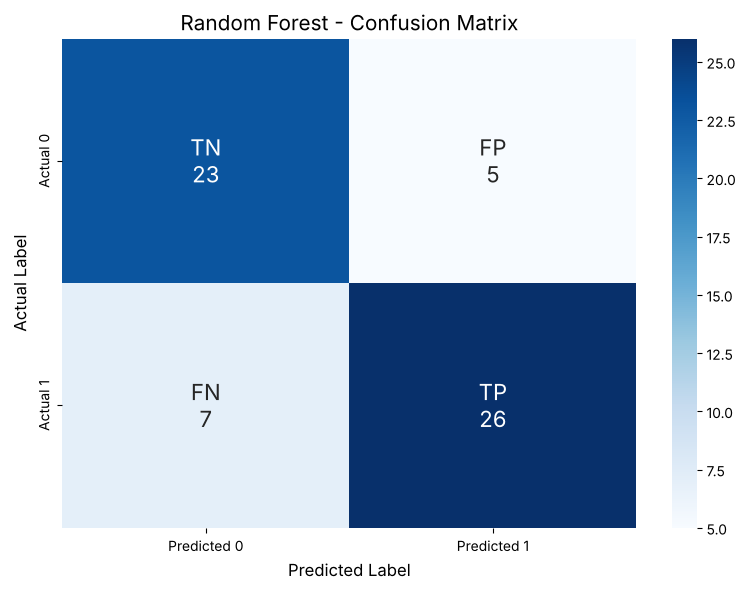

True Negative (TN): 23
False Positive (FP): 5
False Negative (FN): 7
True Positive (TP): 26


In [ ]:
# Confusion matrix heatmap of the BASELINE model on the test set.
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# labels=[0, 1] fixes the order: row/column 0 first, then 1 (class 1 = positive class).
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# ravel() flattens the 2x2 matrix in this order: TN, FP, FN, TP.
tn, fp, fn, tp = cm.ravel()

# Text for each square so the plot shows both the meaning (TN/FP/FN/TP) and the count.
cell_labels = np.array([[f"TN\n{tn}", f"FP\n{fp}"],
                        [f"FN\n{fn}", f"TP\n{tp}"]])

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=cell_labels,
    fmt="",
    cmap="Blues",
    xticklabels=["Predicted 0", "Predicted 1"],
    yticklabels=["Actual 0", "Actual 1"],
    annot_kws={"size": 16}
)

plt.title("Random Forest - Confusion Matrix", fontsize=15)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("Actual Label", fontsize=12)

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"True Negative (TN): {tn}")
print(f"False Positive (FP): {fp}")
print(f"False Negative (FN): {fn}")
print(f"True Positive (TP): {tp}")

### 12 Interpretation — confusion matrix (baseline)
**What was done:** compared the true labels of the 61 test rows with the baseline predictions. Class 1 is the positive class and the label order is `[0, 1]`, so the four squares are:

| | Predicted 0 | Predicted 1 |
|---|---|---|
| **Actual 0** | **TN = 23** (class 0 correctly predicted as 0) | **FP = 5** (class 0 wrongly predicted as 1) |
| **Actual 1** | **FN = 7** (class 1 wrongly predicted as 0) | **TP = 26** (class 1 correctly predicted as 1) |

**What the output shows:** 23 + 5 + 7 + 26 = 61 rows. **49 are correct (TN + TP) and 12 are wrong (FP + FN)**, which matches the accuracy of 0.8033.

**What it means:**
- The model makes more **false negatives (7)** than **false positives (5)**: it misses real class-1 rows slightly more often than it wrongly flags class-0 rows. This is why recall (0.79) is a little lower than precision (0.84).
- Class 0 is found correctly 23 of 28 times (82.1%, the class-0 recall in the report) and class 1 is found correctly 26 of 33 times (78.8%).
- **Implication of errors:** a false negative means a real class-1 row was predicted as class 0; a false positive is the opposite mistake. Which one is worse depends on the true meaning of the labels. If class 1 = disease present (unverified), false negatives are missed cases and are the more serious error.

**Conclusion:** the errors are fairly evenly spread, with a slight tendency to miss class-1 rows. With only 61 test rows, moving 2–3 predictions would change the picture.

## 13. ROC Curve and ROC-AUC (baseline)

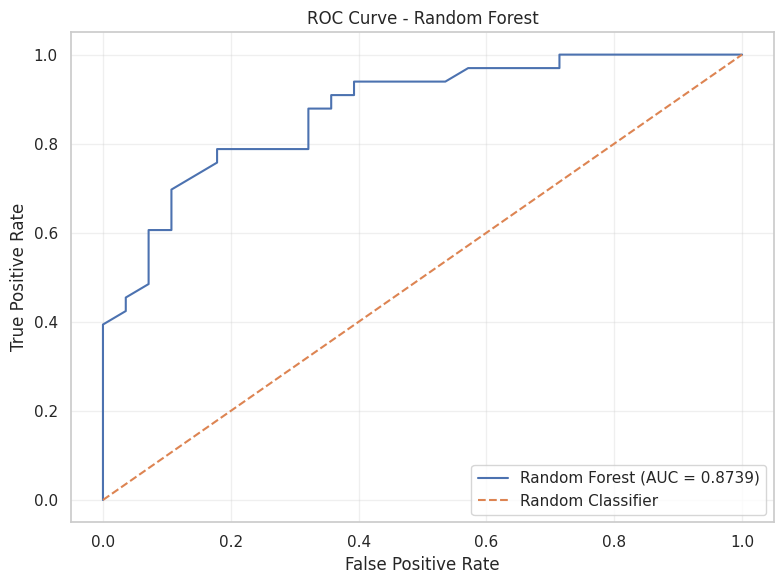

ROC-AUC Score: 0.8739


In [ ]:
# ROC curve of the BASELINE model: shows the trade-off between catching class 1 and raising false alarms.
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# False positive rate and true positive rate at many probability thresholds.
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Area under the ROC curve (1.0 = perfect ranking, 0.5 = random guessing).
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {auc_score:.4f})"
)

# Diagonal dashed line = a classifier that guesses at random.
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Random Forest")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("roc_curve.png", dpi=300, bbox_inches="tight")
plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

### 13 Interpretation — ROC curve and ROC-AUC (baseline)
**What was done:** used the predicted probabilities of class 1 (`y_prob`) to draw the ROC curve (true positive rate vs false positive rate at every possible threshold) and computed the area under it.

**What the output shows:** ROC-AUC = **0.8739**. The curve rises well above the dashed "random" diagonal. Reading the plot: the curve is at a true positive rate of roughly 0.4 when the false positive rate is still 0, about 0.79 at a false positive rate of about 0.18, and about 0.94 at about 0.39. The model's actual predictions (default threshold 0.5) correspond to a true positive rate of 26/33 = 0.79 and a false positive rate of 5/28 = 0.18, which is the point on the curve described above.

**What it means:**
- AUC is the chance that a randomly chosen class-1 row gets a higher predicted probability than a randomly chosen class-0 row. Here that chance is about **87%**. A value of 0.5 would be random guessing and 1.0 would be perfect.
- This is **good ranking ability but not excellent**. It must not be read as "the model is almost perfect".
- The curve is jagged because the test set has only 61 rows, so the AUC itself is uncertain.

**Conclusion:** the baseline separates the two classes clearly better than chance, on this one test split.

## 14. Feature Importance Analysis (baseline model)

     Feature  Importance
2         cp    0.168357
7    thalach    0.132388
11        ca    0.107779
12      thal    0.095283
9    oldpeak    0.092287
0        age    0.082119
4       chol    0.074915
8      exang    0.072822
3   trestbps    0.070633
1        sex    0.039069
10     slope    0.033278
6    restecg    0.023198
5        fbs    0.007871


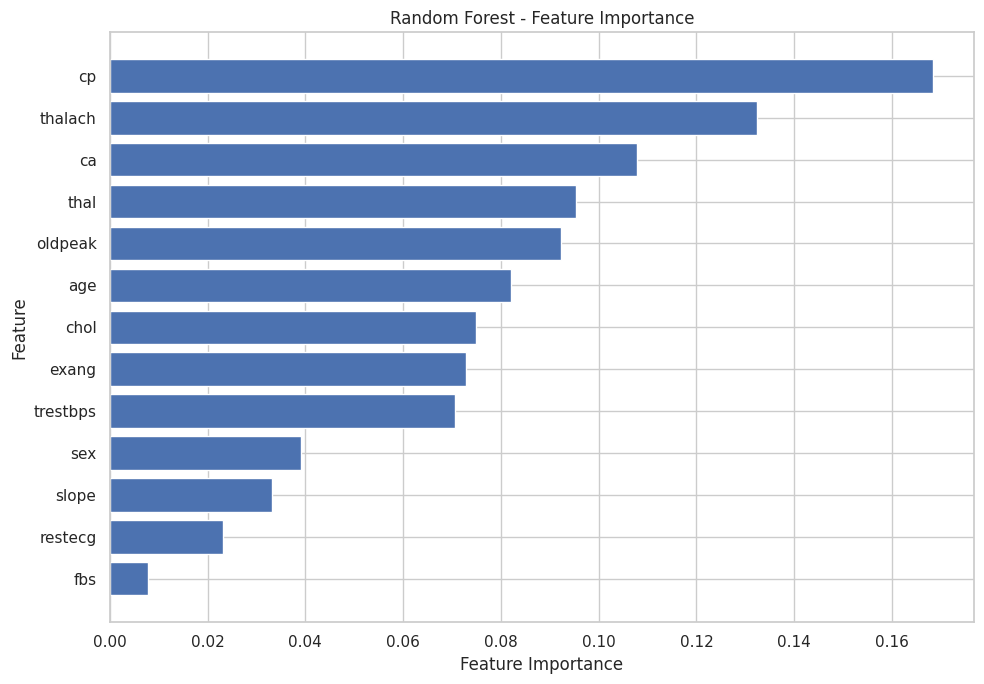

In [ ]:
# Feature importance of the BASELINE model (rf_model): how much each feature helped the trees make their splits.
import pandas as pd
import matplotlib.pyplot as plt

# Put the importance scores in a table next to the feature names.
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features from most to least important.
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df)

# Plot feature importance as a horizontal bar chart (most important feature at the top).
plt.figure(figsize=(10, 7))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig(
    "feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### 14 Interpretation — feature importance (baseline model)
**What was done:** read `feature_importances_` from the trained baseline model `rf_model` (it was trained on the training set only) and ranked the 13 features. The scores add up to 1.

**What the output shows:**
- **Most important:** `cp` (0.168), `thalach` (0.132), `ca` (0.108), `thal` (0.095), `oldpeak` (0.092). These five together make up about **60%** of the total importance.
- **Least important:** `fbs` (0.008), `restecg` (0.023), `slope` (0.033), `sex` (0.039).
- Middle group: `age` (0.082), `chol` (0.075), `exang` (0.073), `trestbps` (0.071).

**What it means:**
- The ranking agrees with the EDA: `cp`, `thalach`, `ca` and `oldpeak` also had strong correlations with `target`, and `fbs` had almost none.
- `sex` correlates with `target` (about −0.28) but ranks low. Importance measures how much the forest *used* a feature, which can be small when other features carry similar information.
- `chol` and `trestbps` rank in the middle even though their correlation with `target` is weak (−0.08 and −0.15). Impurity-based importance is known to favour numerical features with many distinct values, so these middle ranks should not be over-read.

**Important:** feature importance shows what the model *used to predict*. It does **not** show direction (higher or lower), and it does **not** prove that a feature *causes* the label. It also comes from one model on a small training set.

**Conclusion:** chest pain type, maximum heart rate, number of vessels, thalassemia result and ST depression are the main drivers of this model's predictions; fasting blood sugar and resting ECG add very little.

## 15. Hyperparameter Tuning (GridSearchCV)

In [ ]:
# Tune the Random Forest with GridSearchCV. Only the TRAINING set is used, so the test set stays untouched.
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define hyperparameter grid: 2 x 3 x 2 x 2 = 24 combinations to try.
param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

# Initialize model (same class_weight and random_state as the baseline).
rf = RandomForestClassifier(
    random_state=42,
    class_weight="balanced"
)

# Stratified cross-validation: 5 folds, each fold keeps the class proportions.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Grid search using F1-score (24 combinations x 5 folds = 120 fits).
grid_search = GridSearchCV(
    estimator=rf,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Best Cross-Validation F1-score:
0.8833


In [ ]:
# Compare the tuned model's accuracy on the training set and on the test set (to check for overfitting).
# best_model is the best parameter combination, already re-fitted on the full training set by GridSearchCV.
best_model = grid_search.best_estimator_
y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)
print("Train Accuracy:", round(accuracy_score(y_train, y_train_pred), 4))
print("Test Accuracy:", round(accuracy_score(y_test, y_test_pred), 4))

Train Accuracy: 0.9585
Test Accuracy: 0.7705


### 15 Interpretation — hyperparameter tuning
**What was done:** `GridSearchCV` tried 24 parameter combinations (2 values of `n_estimators` × 3 of `max_depth` × 2 of `min_samples_split` × 2 of `min_samples_leaf`) with 5-fold stratified cross-validation on the **training set only** (120 fits in total), scoring each by F1.

**Why:** to see whether a better setting than the default Random Forest exists, without looking at the test set.

**What the output shows:**
- Selected parameters: `max_depth = 5`, `min_samples_leaf = 1`, `min_samples_split = 2`, `n_estimators = 100`.
- Best cross-validation F1-score: **0.8833**.
- Tuned model accuracy: **0.9585 on the training set** vs **0.7705 on the test set**.

**What it means:**
- `min_samples_leaf = 1`, `min_samples_split = 2` and `n_estimators = 100` are the standard defaults, so the **only real change from the baseline is `max_depth = 5`** (the baseline trees grow without a depth limit).
- **0.8833 is a cross-validation score on the training data. It must not be compared with the test-set F1 scores** (baseline 0.8125, tuned 0.7879). It is also the best of 24 tries, so it is somewhat optimistic by construction.
- The tuned model scores 95.85% on rows it was trained on but 77.05% on unseen rows. This **18.8-point gap shows overfitting**: the forest still memorises much of the training data even with depth limited to 5. (The training accuracy of the baseline was not calculated, so this notebook cannot say whether tuning made the gap better or worse.)
- Whether tuning improved held-out performance is judged in Sections 16–17.

**Conclusion:** the search selected a close-to-default model. No further tuning was done after looking at the test set.

## 16. Evaluation of the Tuned Model

In [ ]:
# Evaluate the TUNED model on the same held-out test set, using the tuned model's own predictions and probabilities.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Get the best model from GridSearchCV
best_model = grid_search.best_estimator_

# Predictions on the test set: class labels and probability of class 1.
y_pred_tuned = best_model.predict(X_test)
y_prob_tuned = best_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
print("TUNED RANDOM FOREST RESULTS")
print("-" * 35)

print("Accuracy:", round(accuracy_score(y_test, y_pred_tuned), 4))
print("Precision:", round(precision_score(y_test, y_pred_tuned), 4))
print("Recall:", round(recall_score(y_test, y_pred_tuned), 4))
print("F1-score:", round(f1_score(y_test, y_pred_tuned), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob_tuned), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned))

TUNED RANDOM FOREST RESULTS
-----------------------------------
Accuracy: 0.7705
Precision: 0.7879
Recall: 0.7879
F1-score: 0.7879
ROC-AUC: 0.8528

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.75      0.75        28
           1       0.79      0.79      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



In [ ]:
# Confusion matrix counts of the TUNED model (same label order and positive class as in Section 12).
cm_tuned = confusion_matrix(y_test, y_pred_tuned, labels=[0, 1])
tn_t, fp_t, fn_t, tp_t = cm_tuned.ravel()
print(f"Tuned model -> TN: {tn_t}, FP: {fp_t}, FN: {fn_t}, TP: {tp_t}")

### 16 Interpretation — tuned model on the test set
**What the output shows:** accuracy **0.7705**, precision **0.7879**, recall **0.7879**, F1-score **0.7879**, ROC-AUC **0.8528**. Per class: class 0 has precision 0.75 / recall 0.75; class 1 has precision 0.79 / recall 0.79.

**What it means:**
- Precision and recall are equal (0.7879), so the tuned model is balanced between false alarms and missed class-1 rows.
- Working back from the recorded numbers (recall 0.7879 = 26 of 33, precision 0.7879 = 26 of 33 predicted as class 1, accuracy 47 of 61), the tuned confusion matrix should be **TN = 21, FP = 7, FN = 7, TP = 26**. This is calculated from the metrics, not printed in the earlier run; the small cell above prints the real counts when the notebook is run.
- Compared with the baseline, that means the **same 26 class-1 rows are found (TP), but the tuned model makes 2 more false alarms** (7 instead of 5).

**Conclusion:** the tuned model is slightly weaker than the baseline on this test set. A detailed side-by-side comparison follows.

## 17. Baseline vs Tuned Model Comparison

In [ ]:
# Side-by-side table of all test-set metrics for the baseline and the tuned model.
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Baseline uses y_pred / y_prob; tuned uses y_pred_tuned / y_prob_tuned (both on the same test set).
comparison = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Baseline Random Forest": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ],
    "Tuned Random Forest": [
        accuracy_score(y_test, y_pred_tuned),
        precision_score(y_test, y_pred_tuned),
        recall_score(y_test, y_pred_tuned),
        f1_score(y_test, y_pred_tuned),
        roc_auc_score(y_test, y_prob_tuned)
    ]
})

print(comparison.round(4))

      Metric  Baseline Random Forest  Tuned Random Forest
0   Accuracy                  0.8033               0.7705
1  Precision                  0.8387               0.7879
2     Recall                  0.7879               0.7879
3   F1-score                  0.8125               0.7879
4    ROC-AUC                  0.8739               0.8528


### 17 Interpretation — baseline vs tuned model
| Metric | Baseline | Tuned | Difference (tuned − baseline) |
|---|---|---|---|
| Accuracy | 0.8033 | 0.7705 | −0.0328 |
| Precision | 0.8387 | 0.7879 | −0.0508 |
| Recall | 0.7879 | 0.7879 | 0.0000 |
| F1-score | 0.8125 | 0.7879 | −0.0246 |
| ROC-AUC | 0.8739 | 0.8528 | −0.0211 |

**What the output shows:** the tuned model is **equal on recall and lower on every other metric**.

**What it means:**
- **Hyperparameter tuning did not improve the held-out test performance in this experiment.**
- The accuracy difference equals **2 test predictions** (49 correct vs 47 correct out of 61). That is a very small difference, so this result is **not strong proof that the baseline is truly better**. It only shows there is no evidence that tuning helped.
- Do not mix up the two F1 numbers: the **cross-validation F1 (0.8833)** was measured on training data during tuning; the **test F1 (0.8125 baseline, 0.7879 tuned)** was measured on unseen data. Only the test numbers are compared here.

**Conclusion:** tuning gave no measurable benefit on this test set.

## 18. Final Model Selection
**Selected model: the baseline Random Forest** (`n_estimators=100`, `class_weight="balanced"`, `random_state=42`, default depth).

**Reasons:**
- It has the **higher or equal value on every held-out metric** (accuracy 0.8033, precision 0.8387, F1 0.8125, ROC-AUC 0.8739; recall equal at 0.7879).
- It is the simpler option, with no extra tuning needed.
- The tuned model's cross-validation score cannot overrule the held-out test comparison, because the two scores are measured on different data.

**Honest caveats:**
- The test set is only 61 rows and the gap between the models is only 2 predictions, so the choice is a **sensible default, not a proven winner**.
- The baseline was chosen by looking at test results, so its test scores are **slightly optimistic**. No parameters were adjusted using the test set.
- Neither model is validated for real-world use.

## 19. Conclusion
- **Data:** the original file had 1,025 rows, but **723 were exact duplicates**; only **302 rows** remained. This large reduction is reported openly, and the 302 rows cannot be assumed to be 302 different patients. The data source should be investigated.
- **Overall performance:** the baseline Random Forest reached accuracy **0.8033**, precision **0.8387**, recall **0.7879**, F1-score **0.8125** and ROC-AUC **0.8739** on a held-out test set of 61 rows.
- **Precision and recall trade-off:** precision (0.84) is a little higher than recall (0.79), so the model makes fewer false alarms than missed class-1 rows.
- **Confusion matrix:** TN = 23, FP = 5, FN = 7, TP = 26. There are 12 wrong predictions out of 61, with slightly more false negatives (7) than false positives (5).
- **ROC-AUC:** 0.8739 means good, but not excellent, ability to rank class 1 above class 0. It does not mean the model is almost perfect.
- **Important features:** `cp`, `thalach`, `ca`, `thal` and `oldpeak` (about 60% of total importance together). `fbs` and `restecg` add very little. These are predictive associations. **They do not show causes.**
- **Effect of tuning:** GridSearchCV chose `max_depth=5`, `min_samples_leaf=1`, `min_samples_split=2`, `n_estimators=100` with a cross-validation F1 of 0.8833, but the tuned model did **not** improve test results (accuracy 0.7705, F1 0.7879, ROC-AUC 0.8528). The difference is only 2 predictions in accuracy.
- **Final model:** the baseline Random Forest.
- **Label meaning:** it could not be verified that class 1 means "disease present"; the data pattern suggests it may be the reverse. The medical meaning of the errors is therefore **unconfirmed**.
- This project does **not** show that the model can diagnose patients.

## 20. Limitations
- **Small data after cleaning:** only 302 unique rows, so the model learns from just 241 of them.
- **Small test set:** 61 rows. One prediction changes accuracy by about 1.6 points, and a different random split could give noticeably different scores. The baseline-vs-tuned gap (2 predictions) is within this noise.
- **Duplicates:** 70.5% of the original rows were repeats. The reason is unknown, and unique rows are not proven to be unique patients.
- **Label meaning not verified:** no data dictionary was available, and the data pattern suggests class 1 may not mean "disease present".
- **Single split:** tuning used cross-validation inside the training set, but the baseline was not cross-validated and everything was judged on one test split.
- **Overfitting:** the tuned model scores 0.9585 on training data and 0.7705 on test data.
- **Feature importance:** it comes from one model, tends to favour numerical features, and shows association, not causation.
- **Data coverage:** the data is not balanced between the sex codes (about 68% `sex = 1` after cleaning) and comes from one source; there is no external validation.
- **No clinical validation:** no probability calibration, no cost analysis and no medical review. The model must not be used for real diagnosis.

## 21. Future Improvements
- **Check the data source:** find out why so many rows are repeated and what 0 and 1 really mean in `target`.
- **Use more data:** a larger, documented dataset would give more stable and trustworthy scores.
- **Repeated or stratified cross-validation** for both the baseline and the tuned model, so they are compared on the same footing instead of on one 61-row test set.
- **Permutation importance** (or similar) as a second opinion on which features matter.
- **Threshold tuning:** choose the probability cut-off based on which error matters more, once the label meaning is confirmed.
- **Compare other simple models** (for example logistic regression) as a reference.
- **External validation and expert review** before any real-world use.